<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="figures/cabecalho.jpg" alt="Cabeçalho" style="max-width: 100%; height: auto;">
</div>

# Aplicação de otimização de hiperparâmetros para a predição do índice de refração de materiais inorgânicos

**Autor**: Carlos Gabriel de Oliveira Campos

**Professor**: Dr. Daniel Roberto Cassar

Disciplina de **Aprendizado de Máquina**

---

## A otimização de hiperparâmetros

As capacidades preditivas de modelos computacionais não limitam-se aos algoritmos utilizados, uma vez que o desempenho destes também depende da configuração de hiperparâmetros que lhe é fornecida. Nesse sentido, a busca pelo *melhor* conjunto de hiperparâmetros para os modelos de aprendizado de máquina é uma tarefa inviável de ser realizada na vasta maioria dos casos. Além disso, não é interessante testarmos à mão cada um deles, devido à elevada dimensão e à continuidade do espaço de busca.' Por isso, será empregado o método de otimização bayesiano do *Optuna*, o qual faz testes iniciais de valores para os hiperparâmetros, realizando ajustes conforme a métrica de pontuação varia. No caso deste trabalho, foi escolhida a raiz do erro quadrático médio (RMSE) como métrica de pontuação, visto que ela possibilita a indução de um modelo com melhor capacidade de generalização na predição da propriedade física em questão ao penalizar mais severamente erros maiores, ao passo que erros menores têm menor impacto relativo.

Dessa forma, o trabalho que se segue almeja fundamentar as estratégias aplicadas para a modelagem do índice de refração de materiais inorgânicos por meio de algoritmos de aprendizado de máquina cujos hiperparâmetros foram otimizados. 

## Importações necessárias para o notebook

In [7]:
from matminer.featurizers.structure import DensityFeatures
from matminer.featurizers.composition import ElementProperty
from sklearn.linear_model import LinearRegression, ElasticNet, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.dummy import DummyRegressor
from sklearn.base import clone
from optuna.samplers import TPESampler
from functools import partial
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import optuna
from optuna.trial import TrialState
import optuna.visualization as vis 

### Silenciamento de avisos

In [8]:
from sklearn.exceptions import ConvergenceWarning
import warnings

warnings.filterwarnings("ignore", category=ConvergenceWarning) # aviso caso lasso não convirja
optuna.logging.set_verbosity(optuna.logging.WARNING) # avisos gerais do optuna
np.seterr(over='ignore'); # avisos do numpy

### Importação do dataset

A fonte do dataset utilizado para este trabalho [1], reúne propriedades dielétricas e ópticas de 1.056 compostos inorgânicos cristalinos ordenados (selecionados com band gap > 0,1 eV e até 20 átomos por supercélula), integrados à plataforma Materials Project e disponibilizados originalmente por Petousis et al. (2017). A base fornece os tensores dielétricos (componentes eletrônica, iônica e total) e o índice de refração ($n$) em frequências ópticas, calculados por meio de simulações de primeiros princípios via Teoria do Funcional da Densidade Perturbacional (DFPT) com o funcional GGA/PBE+U.

In [9]:
df = pd.read_pickle("dielectric_constant.pkl")
print(f"Quantidade de valores inválidos: {df.isna().sum().sum()}")

Quantidade de valores inválidos: 0


A princípio, os dados foram carregados para .pkl a partir da API do matminer, conforme o código a seguir (não é necessário rodá-lo para o trabalho):

In [10]:
# from matminer.datasets import load_dataset

# dados_matminer = load_dataset("dielectric_constant")
# dados_matminer.to_pickle("dielectric_constant.pkl")

<span id="estudo-alvo"><span>
## Estudo da variável alvo

É uma boa prática verificar a distribuição do target que buscamos antes de efetivar os modelos de aprendizado, visto que essa análise pode nos guiar na seleção de métricas para avaliar e comparar os modelos.  

In [11]:
y = df.pop("n")
y.describe()

count    1056.000000
mean        2.434886
std         1.148849
min         1.280000
25%         1.770000
50%         2.190000
75%         2.730000
max        16.030000
Name: n, dtype: float64

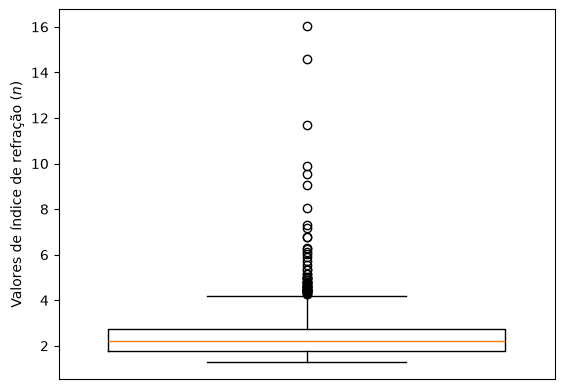

In [12]:
plt.boxplot(y, widths=0.8)
plt.ylabel("Valores de índice de refração $(n)$");
plt.xticks([]);

Como é informado pela descrição `y.describe()` e pelo boxplot, o índice de refração dos materiais tende a ser muito concetrado na faixa de $n \approx 2$, sendo que mais de 75% das observações estão abaixo de 4. Ao mesmo tempo, verifica-se a presença de outliers, com o índice de refração podendo alcançar até mesmo valores acima de 10. Observemos a fração de determinados intervaloa de valores em nossos dados.

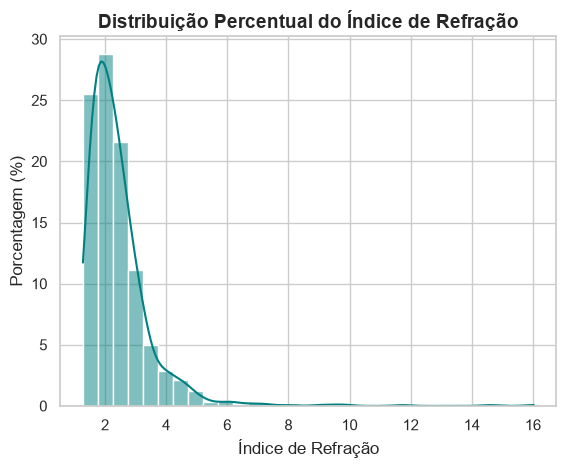

In [14]:
sns.set_theme(style="whitegrid")

sns.histplot(y, kde=True, bins=30, stat="percent", color="teal")

plt.title(
    "Distribuição Percentual do Índice de Refração",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Índice de Refração", fontsize=12)
plt.ylabel("Porcentagem (%)", fontsize=12);

Assim, fica nítido que grande parte das observações concentram-se entre 1 e 4, com uma longa cauda para valores maiores (assimetria positiva).

## Engenharia de atributos e divisão dos dados

O dataset com que estamos trabalhando possui informações sobre a estrutura do material, por exemplo:

Não precismaos entedê-las de primeiro momento, pois o importante é que esses dados são utilizados por ferramentas do matminer para realizar a **extração de atributos**, também conhecida em inglês como *feature extraction*. Nesse contexto, o extrator `DensityFeatures` serve para nos trazer informações sobre a densidade do material, além do volume por átomo e da fração de empacotamento. Já o extrator `ElementProperty`, baseado no banco de dados `magpie` [2], fornece centenas de informações sobre o material com base em sua formulação química, como a eletronegatividade média (`mean`) e a energia do *bandgap* no estado fundamental (`GSbandgap`).

In [15]:
# Instancia extratores
dens_feat = DensityFeatures()
magpie_feat = ElementProperty.from_preset("magpie")

# Extrai features de densidade e da estrutura química 
features_combinadas = [
    dens_feat.featurize(s) + magpie_feat.featurize(s.composition) 
    for s in df["structure"]
]
labels_combinados = dens_feat.feature_labels() + magpie_feat.feature_labels()

# Cria df apenas com features extraídas para depois juntar ao principal
df_features = pd.DataFrame(features_combinadas, columns=labels_combinados, index=df.index)

X = pd.concat([df, df_features], axis=1)

### Exclusão de atributos irrelevantes ou causados pelo target

Por exemplo, `structure` é uma matriz de informações a partir da qual outras features são extraídas com as ferramentas do matminer. Já o índice de refração, `n`, está relacionado diretamente com o  target `poly_electronic` ($\varepsilon_{\infty}$), visto que $n \approx \sqrt{\epsilon}$ em materiais não magnéticos [3].

In [16]:
features_excluidas = ["cif", "material_id", "meta", "poscar", "structure", 
    "space_group", "formula", "e_electronic", "e_total", "poly_total", "poly_electronic"]

X.drop(features_excluidas, axis=1, inplace=True);

### Processamento de coluna categórica

Nossos dados apresentam a coluna categórica booleana `pot_ferroelectric`, a qual indica se o material analisado tem o potencial de ser ferroelétrico. Assim, o pré-processamento dos atributos deverá ser diferenciado para aqules quantitativos numéricos e aquele categórico booleano (todos os dados se limitam a esses tipos). Nesse caso, o atributo categórico será transformado em uma única coluna de 0s e 1s por meio do `OneHotEncoder` que rodará pelo `preprocessor`.

In [17]:
# Definição do atributo categórico
coluna_categorica = ['pot_ferroelectric']

# Codifica apenas categorica para 0 e 1, deixando apenas uma delas no final.
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), coluna_categorica)
    ],
    remainder='passthrough'
)

### Divisão treino-teste

O método de *Holdout* será aplicado para definir o conjunto fixo de treino e de teste para todo o trabalho. Contudo, essa divisão será realizada de modo que materiais que partilhem da mesma fórmula química não sejam alocados a ambos os conjuntos, visando evitar o vazamento de dados. Dada a proporção dos dados de cerca de 1000 exemplos, serão reservados 20% destes para teste e os demais para treino.

In [18]:
TAMANHO_TESTE = 0.2
SEMENTE_ALEATORIA = 42

grupos = df['formula']

# 2. Configurar o separador de grupos
gss = GroupShuffleSplit(
    n_splits=1, 
    test_size=TAMANHO_TESTE,
    random_state=SEMENTE_ALEATORIA
)

for idx_treino, idx_teste in gss.split(X, y, groups=grupos):
    x_treino = X.iloc[idx_treino]
    x_teste = X.iloc[idx_teste]
    y_treino = y.iloc[idx_treino]
    y_teste = y.iloc[idx_teste]
    
    # Evita data leakage ao dividir pela formula das obs. de treino
    grupos_treino = grupos.iloc[idx_treino]

desv_padrao_treino = y_treino.std()

## Abordagem geral para a indução dos modelos

Tendo estudado e prepararado nossos dados, chega a hora de arquitetar a indução dos modelos de aprendizado de máquina e como serão construídos os *pipelines*.

### Validação Cruzada K-Fold

Os resultados de desempenho de um modelo podem variar não somente de acordo com as competências do modelo em si, mas também de acordo com os dados sobre os quais ele é treinado. Assim,um mesmo modelo pode apresentar métricas incríveis, assim como razoáveis, a depender da divisão de treino e teste realizada. Para mitigar essa ação do acaso, a validação cruzada K-Fold é uma técnica que subdivide o conjunto de treino em K *folds*, deixando um deles para testar o modelo e os demais para treiná-lo. Dessa forma, obtém-se uma estimativa mais robusta do erro de um modelo, possibilitando uma análise mais embasada. O padrão de aplicação geralmente utilzia 5 folds, o que será mantido aqui.

### Filtro de atributos com *variância quase nula*

Conforme [4], atributos com variância nula ou quase nula (near-zero variance - NZV) apresentam distribuições degeneradas que podem ser prejudiciais a modelos lineares, provocando erros computacionais, influência desproporcional de poucas amostras e degeneração total da variável durante procedimentos de reamostragem (como a validação cruzada, na qual uma partição de treino pode passar a conter apenas um valor único). Segundo os critérios estabelecidos em [4], esses preditores caracterizam-se simultaneamente por uma baixa fração de valores únicos em relação ao tamanho amostral ($\le 10\%$) e por uma elevada razão entre a frequência do valor mais prevalente e a do segundo mais prevalente ($\ge 20$). 

Aplicando esse critério ao conjunto de dados, foram identificados 23 atributos que se enquadravam nessa descrição, como mostra o código a seguir:

In [19]:
X_num = X.select_dtypes(include="number")
num_amostras = len(X_num)

def eh_nzv(col, freq_cut=20.0, unique_cut=0.10):
    contagens = col.value_counts(dropna=True)
    n_unicos = len(contagens)
    if n_unicos <= 1:
        return True
    pct_unicos = n_unicos / num_amostras
    razao_freq = contagens.iloc[0] / contagens.iloc[1]
    return (pct_unicos <= unique_cut) and (razao_freq >= freq_cut)

mascara_nzv = X_num.apply(eh_nzv)

colunas_filtradas = (
    X_num.loc[:, mascara_nzv].apply(lambda col: col.value_counts(normalize=True).iloc[0])
    if mascara_nzv.any()
    else pd.Series(dtype=float)
)

print("Atributo" + " "*25 + "Frequência da moda")
colunas_filtradas

Atributo                         Frequência da moda


MagpieData maximum NsValence     0.991477
MagpieData minimum NfValence     1.000000
MagpieData mean NfValence        0.819129
MagpieData avg_dev NfValence     0.819129
MagpieData mode NfValence        0.997159
MagpieData minimum NsUnfilled    0.992424
MagpieData minimum NdUnfilled    1.000000
MagpieData mean NdUnfilled       0.700758
MagpieData avg_dev NdUnfilled    0.700758
MagpieData mode NdUnfilled       0.997159
MagpieData minimum NfUnfilled    1.000000
MagpieData maximum NfUnfilled    1.000000
MagpieData range NfUnfilled      1.000000
MagpieData mean NfUnfilled       1.000000
MagpieData avg_dev NfUnfilled    1.000000
MagpieData mode NfUnfilled       1.000000
MagpieData minimum GSbandgap     0.951705
MagpieData minimum GSmagmom      1.000000
MagpieData maximum GSmagmom      0.882576
MagpieData range GSmagmom        0.882576
MagpieData mean GSmagmom         0.882576
MagpieData avg_dev GSmagmom      0.882576
MagpieData mode GSmagmom         0.998106
dtype: float64

Desse modo, foi criado com o auxílio do Gemini o seguinte filtro de atributos do tipo NZV, o qual será incorporado a todos os pipelines a fim de remover estes atributos na etapa de pré-processamento, assegurando a estabilidade numérica dos modelos.

In [20]:
class FiltroNZV(BaseEstimator, TransformerMixin):
    """
    Filtro de preditores com variância quase nula (Near-Zero Variance).
    """
    def __init__(self, freq_cut=20.0, unique_cut=0.10):
        self.freq_cut = freq_cut
        self.unique_cut = unique_cut

    def fit(self, X, y=None):
        # Converte para DataFrame temporariamente para facilitar os cálculos,
        # garantindo compatibilidade mesmo se o Pipeline passar um array NumPy.
        df = pd.DataFrame(X)
        n_amostras = len(df)
        
        mascara = []
        
        for col in df.columns:
            # Conta a frequência dos valores (ignorando NaNs)
            contagens = df[col].value_counts(dropna=True)
            n_unicos = len(contagens)
            
            # 1. Critério de Variância Zero (constante ou totalmente vazia)
            if n_unicos <= 1:
                mascara.append(False)  # Falso = Descartes a coluna
                continue
                
            # 2. Critério de Variância Quase Nula (NZV)
            pct_unicos = n_unicos / n_amostras
            razao_freq = contagens.iloc[0] / contagens.iloc[1]
            
            # Se atender aos DOIS critérios de Kuhn & Johnson, é NZV
            is_nzv = (pct_unicos <= self.unique_cut) and (razao_freq >= self.freq_cut)
            
            # Guardamos True para manter a coluna, False para descartar
            mascara.append(not is_nzv)
            
        # Salva a máscara de colunas aprovadas no estado do objeto
        self.mascara_manter_ = np.array(mascara)
        return self

    def transform(self, X):
        # Verifica se o fit já foi chamado
        if not hasattr(self, "mascara_manter_"):
            raise RuntimeError("O transformador precisa ser ajustado (fit) antes do transform.")
        
        # Se for DataFrame, usa .loc para fatiar e manter os nomes das colunas
        if isinstance(X, pd.DataFrame):
            return X.loc[:, self.mascara_manter_]
        
        # Se o scikit-learn já tiver convertido para NumPy array, fatia diretamente
        return X[:, self.mascara_manter_]

    def get_feature_names_out(self, input_features=None):
        # Método utilitário para você conseguir recuperar os nomes das colunas 
        # que sobreviveram ao filtro depois que o Pipeline rodar.
        if input_features is None:
            return None
        return np.array(input_features)[self.mascara_manter_]

<span id="combinacao-pruning"><span>
### Combinação de técnicas com *pruning*

Os *trials* (tentativas) realizados pelo optuna serão respaldados pela validação cruzada 5-Fold a fim de selecionar o modelo com melhor capacidade de generalização. Entretanto, esse esforço extra é mais custoso computacionalmente, o que pode exigir alguma forma de otimização. Para isso, entra o método de *pruning*, o qual analisa etapas do nosso trial para decidir se este deve ser continuado ou pulado para o próximo. No nosso caso, cada etapa de um trial será representada pelo treinamento e avaliação sobre cada um dos 5 folds, de modo que a partir do terceiro, a média do desempenho dos folds será comparada à média do desempenho de folds de outros trials passados. Assim, o trial só continuará a ser avaliado caso não esteja abaixo da média, o que poupa recursos computacionais e tempo, embora dê um pouco mais de espaço para que o acaso *puxe nosso tapete*.

### Padronização z-score

Entre as várias dezenas de atributos que nós temos agora à disposição, eles apresentam diferentes magnitudes. Isso é um empecilho quando estamos tratando de modelos baseados em regularização, como Ridge e Lasso, uma vez que seu termo de penalização depende dos valores dos coeficientes, que variam conforme a magniutde do atributo correspodente e seu impacto para a resposta. Nesse contexto, sendo $\mu$ a média da variável $X$ e $\sigma$ seu desvio padrão, a padronização z-score é definida como

$$
z = \frac{x - \mu}{\sigma},
$$

oferecendo uma solução para esse problema ao centralizar a variável e então padronizá-la de acordo com seu desvio padrão. Em nosso código, essa transformação será realizada por meio de `StandardScaler`, cuja aplicação estará sob o comando do optuna. 

### Transformação Logarítmica

Como vimos na seção [Estudo da variável alvo](#estudo-alvo), a distribuição do nosso target apresenta uma curva significativa para valores elevados do índice de refração, revelando *outliers*. Como vamos guiar nossa otimização de hiperparâmetros pela RMSE, a presença de valores muito maiores do que a média pode prejudicar o desempenho do modelo para os dados no coração da distribuição, uma vez que o modelo tenta se equilibrar entre eles. 

Em vista disso, a transformação logarítmica demonstra um potencial ao encurtar essas distâncias, ao mesmo tempo que pode não ser muito interessante, caso o target não seja disperso o suficiente. No primeiro cenário, essa transformação contribui para o desempenho do modelo ao reduzir a *heteroscedasticidade* dos resíduos, dessa forma guiando a indução dos modelos para uma maior generalização dos dados, com menor influência da diferença de escalas na própria variável-alvo. 

Por isso, será usado o *wrapper* (envelopador) `TransformedTargetRegressor`, cuja atuação, sob as configurações neste trabalho, aplica a transformação $Y^* = \text{log}(Y + 1)$ antes do treinamento e reverte a transformação posteriormente por meio de $Y = e^{Y^*} - 1$. Os ajustes com $+1$ e $-1$ servem para evitar o erro ao calcular $log(0)$ e garantir a reversibilidade correta dos valores das variável.  

## Funções gerais de suporte

Visando evitar grandes repetições de código por todo o trabalho, vamos definir três funções principais de suporte que servirão para instanciar os pipelines necessários, para definir a função objetivo global e uma padronização na otimização dos hiperparâmetros.

### Função geral de instanciação de pipeline do modelo

Todos os modelos a seguir terão como opção de escolha pelo optuna a aplicação da transformação log (para o target), bem como o PCA. Assim, vamos definir uma única função que receberá um `algoritmo` (como Ridge ou RandomForest), seus `parametros` a serem definidos pelas sugestões do trial do optuna (ex.: `"alpha": trial.suggest_float("alpha", 0.01, 1_000, log=True)`) e o `trial` em questão. 

Dessa maneira, a função `instancia_pipeline` complementará o pipeline do modelo gerado com as transformações adicionais caso elas sejam desejadas pelo otimizador do optuna. 

In [21]:
def instancia_pipeline(trial, algoritmo, parametros):
    """Constrói um Pipeline do Scikit-Learn integrando pré-processamento e o modelo.

    Atua como uma fábrica (Factory) que padroniza o pipeline base
    (preprocessor + VarianceThreshold) e adiciona dinamicamente transformações de
    atributos (PCA) e do alvo (TransformedTargetRegressor com log1p/expm1)
    conforme as escolhas de hiperparâmetros sugeridas pelo Optuna.

    Parameters
    ----------
    trial : optuna.Trial
        Objeto de tentativa do Optuna utilizado paraamostrar decisões
        arquiteturais (ex: usar PCA e/ou transformação logarítmica).
    algoritmo : type
        Classe do regressor do Scikit-Learn a ser instanciada (ex: Ridge,
        KernelRidge, SVR, RandomForestRegressor).
    parametros : dict
        Dicionário contendo os hiperparâmetros específicos do algoritmo já
        amostrados pelo Optuna.

    Returns
    -------
    sklearn.pipeline.Pipeline
        Pipeline completo configurado com pré-processamento, seleção/redução de
        dimensionalidade opcional e o regressor envelopado.
    """

    # Define etapas fudnamentais do pipeline
    etapas_pipe = [preprocessor, FiltroNZV(freq_cut=20.0, unique_cut=0.10)]

    #  Adiciona StandardScaler ao pipeline caso optuna escolha usá-lo
    usa_padronizador = trial.suggest_categorical('usar_padronizador', [True, False])
    if usa_padronizador:
        etapas_pipe.append(StandardScaler())

    # Adiciona PCA ao pipeline caso optuna escolha usá-lo
    usa_pca = trial.suggest_categorical('usar_pca', [True, False])
    if usa_pca:
        num_componentes_pca = trial.suggest_int('num_componentes', 10, 70)
        etapas_pipe.append(
            PCA(
                n_components=num_componentes_pca, 
                random_state=SEMENTE_ALEATORIA 
                )
        )

    # versão "base" do modelo
    modelo = algoritmo(**parametros)

    # Atualiza modelo caso optuna deseja usar transformação log
    transforma_log = trial.suggest_categorical("transforma_log", [True, False])
    if transforma_log:
        modelo = TransformedTargetRegressor(
            regressor=modelo,
            func=np.log1p,
            inverse_func=np.expm1
        )
    # Por último, adiciona o modelo à lista do pipeline
    etapas_pipe.append(modelo)

    return make_pipeline(*etapas_pipe)

### Função geral de objetivo

Será definida uma única função objetivo, a qual deverá servir para todos os modelos deste trabalho. Ela integra a lógica da validação cruzada 5-Fold ao pruning, como comentado em [Combinando técnicas com *pruning*](#combinacao-pruning). Ela funciona de modo que ela recebe o `trial` com todos os hiperparâmetros e configurações para a indução do modelo, definido pela `funcao_instania`, que então é ajustado a partir e tão somente dos dados de treino (`X` e `y`), além da informação sobre os grupos de dados `grupos` e o número de folds para a validação cruzada `num_folds`.

In [22]:
def funcao_objetivo(trial, funcao_instancia, X, y, grupos, num_folds):
    """Função objetivo genérica para otimização com validação cruzada por grupos.

    Executa a avaliação de um modelo via GroupKFold mantendo a integridade dos
    grupos químicos entre treino e validação. Inclui tratamento de erros numéricos
    (overflow na reconstrução exponencial do log) e integra a poda antecipada
    (pruning) do Optuna passo a passo a cada fold.

    Parameters
    ----------
    trial : optuna.Trial
        Objeto de tentativa do Optuna contendo o estado da otimização atual.
    funcao_instancia : callable
        Função fábrica responsável por receber o `trial` e retornar um Pipeline
        configurado (ex: `instancia_pipe_ridge`).
    X : pandas.DataFrame ou numpy.ndarray
        Matriz de atributos de treino.
    y : pandas.Series ou numpy.ndarray
        Vetor da variável alvo de treino.
    grupos : array-like
        Identificadores dos grupos (ex: fórmulas químicas) usados para divisão do GroupKFold.
    num_folds : int
        Número de fatias (folds) para a validação cruzada.

    Returns
    -------
    float
        Média do RMSE (Root Mean Squared Error) obtida nos folds de validação.

    Raises
    ------
    optuna.TrialPruned
        Se a predição gerar valores numéricos inválidos (infinito/overflow no expm1)
        ou se o podador (pruner) determinar que a tentativa corrente tem desempenho
        inferior ao histórico.
    """

    modelo_base = funcao_instancia(trial)

    metricas = []

    gkf = GroupKFold(num_folds)

    for passo, fold in enumerate(gkf.split(X, y, groups=grupos)):

        indice_treino, indice_teste = fold

        X_treino_, X_teste_ = X.iloc[indice_treino], X.iloc[indice_teste]
        y_treino_, y_teste_ = y.iloc[indice_treino], y.iloc[indice_teste]

        modelo = clone(modelo_base)
        modelo.fit(X_treino_, y_treino_)
        
        y_verdadeiro = y_teste_
        
        try:
            y_previsto = modelo.predict(X_teste_)
            RMSE = root_mean_squared_error(y_verdadeiro, y_previsto)
        except ValueError:
            # Se a predição estourar o limite numérico (infinito), aborta esta tentativa
            raise optuna.TrialPruned()

        metricas.append(RMSE)
        trial.report(np.mean(metricas), passo)

        if trial.should_prune():
            raise optuna.TrialPruned()

    return np.mean(metricas)

### Função geral de aplicação de otimização de hiperparâmetros

A aplicação de otimização também será padronizada entre os modelos po rmeio de uma função única para essa tarefa. Ela opera ao receber um `pipeline`, os dados de treino `X` e `y`,o nome do estudo `nome_estudo` que será gerado e o número de tentativas que serão executadas `num_trials`, cujo valor é 100 por pardão. Como resultado, ela retorna o objeto de estudo correspodente.

In [23]:
def otimiza_hiper(pipeline, X, y, grupos, nome_estudo, num_trials=100):
    """Gerencia e executa o estudo de otimização de hiperparâmetros no Optuna.

    Configura o banco de dados SQLite para persistência dos resultados, inicializa
    o podador (`MedianPruner`) e o amostrador (`TPESampler`), mapeia a função objetivo
    via `partial` e executa as tentativas de otimização.

    Parameters
    ----------
    pipeline : callable
        Função de fábrica específica do modelo que recebe um `trial` e retorna o
        pipeline montado (ex: `instancia_pipe_ridge`).
    X : pandas.DataFrame
        Conjunto de dados de entrada de treino.
    y : pandas.Series
        Variável alvo de treino.
    grupos : array-like
        Identificadores dos grupos para a divisão do GroupKFold.
    nome_estudo : str
        Nome identificador do estudo no Optuna (utilizado também para o arquivo .db).
    num_trials : int, optional
        Quantidade total de tentativas (trials) a serem executadas (default é 100).

    Returns
    -------
    optuna.study.Study
        Objeto do estudo do Optuna concluído, contendo o histórico de tentativas,
        métricas e o `best_trial`.
    """

    NUM_TRIALS_AQUECIMENTO = 5
    NUM_PASSOS_AQUECIMENTO = 3
    NUM_FOLDS = 5

    PODADOR = optuna.pruners.MedianPruner(
        n_startup_trials=NUM_TRIALS_AQUECIMENTO,
        n_warmup_steps=NUM_PASSOS_AQUECIMENTO,
    )

    estudo = optuna.create_study(
        direction="minimize",
        study_name=nome_estudo,
        storage=f"sqlite:///optuna_files/{nome_estudo}.db",
        load_if_exists=True,
        sampler=TPESampler(),
        pruner=PODADOR,
    )

    funcao_parcial = partial(
        funcao_objetivo,
        funcao_instancia=pipeline,
        X=X,
        y=y,
        grupos=grupos,
        num_folds=NUM_FOLDS
    )

    estudo.optimize(funcao_parcial, n_trials=num_trials)

    return estudo

### Função de suporte para apresentar transformações

In [24]:
def resultados_transformacoes(trial):
    transforma_log = trial.params.get('transforma_log')
    padronizacao = trial.params.get('usar_padronizador')

    if transforma_log:
        msg_log = "Aplicada"
    else:
        msg_log = "Ausente" 

    if padronizacao:
        msg_padronizacao = "Aplicada"
    else:
        msg_padronizacao = "Ausente" 

    msg_pca = trial.params.get('num_componentes', 'Ausente')
    
    return msg_log, msg_padronizacao, msg_pca


### Função de suporte para calcular métricas de desempenho

In [25]:
def calcula_desempenho(y_teste, y_previsao, desv_padrao):
    RMSE = root_mean_squared_error(y_teste, y_previsao)
    NMRSE = 100 * RMSE / desv_padrao
    R2 = r2_score(y_teste, y_previsao)
    
    return RMSE, NMRSE, R2

## Estabelecendo Baseline

Tendo preparado os dados e as funções de suporte, chegou a hora de aplicar nossos modelos para prever o índice de refração dos materiais. Usemos a regressão linear para estabelecer um mínimo comparativo de desempenho, visto que ela é um método linear relativamente simples e que prescinde de hiperparâmetros.

### Regressão Linear

In [26]:
reglin = LinearRegression()
reglin.fit(x_treino, y_treino)
previsao = reglin.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

print(
    f"\n{'='*50}",
    " "*7 + "RESULTADOS DO MODELO REGRESSÃO LINEAR",
    f"{'='*50}",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE     : {RMSE:.3f}",
    f" • NRMSE_σ  : {NMRSE:.3f}",
    f" • R²       : {R2:.3f}",
    f"{'='*50}\n",
    sep="\n"
)


       RESULTADOS DO MODELO REGRESSÃO LINEAR

[ Métricas de Desempenho ]
 • RMSE     : 0.655
 • NRMSE_σ  : 55.648
 • R²       : 0.592



## Implementando otimização de hiperparâmetros

Serão treinados ao total 6 algoritmos, sendo estes regressão Ridge, regressão LASSO, ElasticNet, Floresta Aleatória, Support Vector Regressor (SVR) e Kernel Ridge Regressor (KRR). A seção de todos eles contará com a função de instanciação correspondente, seguida pelo código para otimização com 100 tentativas (trials) e visualização dos resultados. Em seguida, estarão disponíveis os resultados obtidos ao rodar mil trials por um HPC, cujo código para o arquivo de job `.sh` e de python `.py` estão disponíveis no diretório `hpc_files` deste repositório (TODO). 

### Regressão Ridge

#### Definindo função de instanciação do modelo

O hiperparâmetro `alpha` controla a penalidade sobre a soma dos valores de coeficientes, de modo que quanto maior alpha, maior será o encolhimento dos coeficientes. Entretanto, diferentemente da regressão LASSO, a regressão Ridge não realiza seleção de atributos isto é, não encolhe o valor coeficientes a 0.

In [27]:
def instancia_pipe_ridge(trial):
    parametros = {
        # espaço de busca
        "alpha": trial.suggest_float("alpha", 0.01, 1_000, log=True)
    }

    return instancia_pipeline(trial, Ridge, parametros)

#### Otimizando com 100 trials

In [147]:
NUM_TENTATIVAS = 100

estudo_ridge2 = otimiza_hiper(
    instancia_pipe_ridge, 
    X=x_treino, y=y_treino, 
    grupos=grupos_treino, 
    nome_estudo="ridge_poda2",
    num_trials=NUM_TENTATIVAS
)

#### Verificando resultados

In [149]:
melhor_trial = estudo_ridge2.best_trial

ridge = instancia_pipe_ridge(melhor_trial)
ridge.fit(x_treino, y_treino)

previsao = ridge.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO RIDGE",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • Alpha (Regularização)  : {melhor_trial.params['alpha']:.4f}",
    
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",

    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO RIDGE
Trial vencedor : #12

[ Hiperparâmetros Otimizados ]
 • Alpha (Regularização)  : 16.5372

[ Transformações selecionadas ]
 • Padronização          : Aplicada
 • Transformação Log     : Aplicada
 • Componentes PCA       : Ausente

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.7303  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.6042
 • NRMSE (Teste Final)       : 51.35%
 • R² (Teste Final)         : 0.6529



#### Resultados do HPC

In [28]:
NOME_ESTUDO = "ridge_poda"
caminho = f"sqlite:///optuna_files/{NOME_ESTUDO}.db"

estudo_hpc = optuna.load_study(
    study_name=NOME_ESTUDO,
    storage=caminho
)

melhor_trial = estudo_hpc.best_trial

ridge = instancia_pipe_ridge(melhor_trial)
ridge.fit(x_treino, y_treino)
previsao = ridge.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO RIDGE",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • Alpha (Regularização)  : {melhor_trial.params['alpha']:.4f}",
    
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",

    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO RIDGE
Trial vencedor : #261

[ Hiperparâmetros Otimizados ]
 • Alpha (Regularização)  : 10.4379

[ Transformações selecionadas ]
 • Padronização          : Aplicada
 • Transformação Log     : Aplicada
 • Componentes PCA       : Ausente

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.7298  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.6035
 • NRMSE (Teste Final)       : 51.30%
 • R² (Teste Final)         : 0.6537



In [26]:
vis.plot_param_importances(estudo_hpc)

Como a transformação logarítmica apresentou uma importância muito grande, ofuscando as demais. Isso indica que ela foi essencial para o desempenho do modelo, ao passo que o único hiperparâmetro que compõe o alpha foi o último em escala de importância, atrás de todas as transformações.

In [29]:
vis.plot_optimization_history(estudo_hpc)


Possivelmente em razão da simplicidade do modelo (apenas 1 hiperparâmetro e as 3 transformações), o optuna rapidamente encontrou seu melhor resultado, obtendo resultados muito próximos ao do melhor trial 261 já na faixa da primeira centena.

### Lasso

#### Definindo função de instanciação do modelo

A regressão Lasso partilha do mesmo e único hiperparâmetro: `alpha`, que controla a magnitude dos coeficientes associados aos preditores. Entretanto, sua capacidade de realizar a seleção de atributos ao encolher coeficientes a 0 possibilita um melhor aprendizado para cojuntos de dados esparsos.

In [30]:
def instancia_pipe_lasso(trial):
    parametros = {
        # espaço de busca
        "alpha": trial.suggest_float("alpha", 1e-4, 100, log=True),
        # argumento fixo
        "max_iter": 10_000
    }

    return instancia_pipeline(trial, Lasso, parametros)

#### Otimizando com 100 trials

In [ ]:
estudo_lasso = otimiza_hiper(
    instancia_pipe_lasso, 
    X=x_treino, y=y_treino, 
    grupos=grupos_treino, 
    nome_estudo="lasso_poda",
    num_trials=NUM_TENTATIVAS
)

#### Verificando resultados

In [38]:
melhor_trial = estudo_lasso.best_trial

lasso = instancia_pipe_lasso(melhor_trial)
lasso.fit(x_treino, y_treino)
previsao = lasso.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO LASSO",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[Transformações e Hiperparâmetros Otimizados]",
    f" • Alpha (Regularização)  : {melhor_trial.params['alpha']:.4f}",
    
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)

NameError: name 'estudo_lasso' is not defined

#### Resultados do HPC

In [31]:
NOME_ESTUDO = "lasso_poda"
caminho = f"sqlite:///optuna_files/{NOME_ESTUDO}.db"

estudo_hpc = optuna.load_study(
    study_name=NOME_ESTUDO,
    storage=caminho
)

melhor_trial = estudo_hpc.best_trial

lasso = instancia_pipe_lasso(melhor_trial)
lasso.fit(x_treino, y_treino)

previsao = lasso.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO LASSO",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[Transformações e Hiperparâmetros Otimizados]",
    f" • Alpha (Regularização)  : {melhor_trial.params['alpha']:.4f}",
    
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO LASSO
Trial vencedor : #462

[Transformações e Hiperparâmetros Otimizados]
 • Alpha (Regularização)  : 0.0012

[ Transformações selecionadas ]
 • Padronização          : Aplicada
 • Transformação Log     : Aplicada
 • Componentes PCA       : Ausente

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.7248  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.6081
 • NRMSE (Teste Final)       : 51.69%
 • R² (Teste Final)         : 0.6483



In [68]:
vis.plot_optimization_history(estudo_hpc)


In [62]:
vis.plot_param_importances(estudo_hpc)

### ElasticNet

#### Definindo função de instanciação do modelo

In [40]:
def instancia_pipe_elasticnet(trial):
    parametros = {
        # espaço de busca
        "alpha": trial.suggest_float("alpha", 1e-4, 1_000, log=True),
        "l1_ratio": trial.suggest_float("l1_ratio", 0, 1),
        # argumento fixo
        "max_iter": 10_000
    }

    return instancia_pipeline(trial, ElasticNet, parametros)

In [ ]:
estudo_elasticnet = otimiza_hiper(
    instancia_pipe_elasticnet, 
    X=x_treino, y=y_treino, 
    grupos=grupos_treino, 
    nome_estudo="elasticnet_poda",
    num_trials=20
)

#### Otimizando com 100 trials

In [ ]:
melhor_trial = estudo_elasticnet.best_trial

elasticnet = instancia_pipe_elasticnet(melhor_trial)
elasticnet.fit(x_treino, y_treino)

previsao = elasticnet.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO ElasticNet",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[Transformações e Hiperparâmetros Otimizados]",
    f" • Alpha (Regularização)  : {melhor_trial.params['alpha']:.4f}",
    f" • L1 Ratio : {melhor_trial.params['l1_ratio']:.3f} (0 = Ridge puro | 1 = Lasso puro)",
    
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)

#### Resultados HPC

In [41]:
NOME_ESTUDO = "elasticnet_poda"
caminho = f"sqlite:///optuna_files/{NOME_ESTUDO}.db"

estudo_hpc = optuna.load_study(
    study_name=NOME_ESTUDO,
    storage=caminho
)

melhor_trial = estudo_hpc.best_trial

elasticnet = instancia_pipe_elasticnet(melhor_trial)
elasticnet.fit(x_treino, y_treino)

previsao = elasticnet.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO ElasticNet",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[Transformações e Hiperparâmetros Otimizados]",
    f" • Alpha (Regularização)  : {melhor_trial.params['alpha']:.4f}",
    f" • L1 Ratio : {melhor_trial.params['l1_ratio']:.3f} (0 = Ridge puro | 1 = Lasso puro)",
    
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO ElasticNet
Trial vencedor : #954

[Transformações e Hiperparâmetros Otimizados]
 • Alpha (Regularização)  : 0.0013
 • L1 Ratio : 1.000 (0 = Ridge puro | 1 = Lasso puro)

[ Transformações selecionadas ]
 • Padronização          : Aplicada
 • Transformação Log     : Aplicada
 • Componentes PCA       : Ausente

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.7248  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.6082
 • NRMSE (Teste Final)       : 51.69%
 • R² (Teste Final)         : 0.6482



In [ ]:
vis.plot_optimization_history(estudo_hpc)

In [ ]:
vis.plot_param_importances(estudo_hpc)

### Floresta Aleatória

#### Definindo função de instanciação do modelo

In [42]:
def instancia_pipe_floresta_aleatoria(trial):

    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("num_arvores", 5, 300, log=True),
        "criterion": trial.suggest_categorical("critério", ["squared_error", "absolute_error", "poisson"]),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 20),
        "max_features": trial.suggest_float("num_max_atributos", 0, 1),
        # argumentos fixos
        "n_jobs": -1,
        "bootstrap": True,
        "random_state": SEMENTE_ALEATORIA,
    }

    return instancia_pipeline(trial, RandomForestRegressor, parametros)

#### Otimizando com 100 trials

In [ ]:
estudo_floresta_aleatoria = otimiza_hiper(
    instancia_pipe_floresta_aleatoria, 
    X=x_treino, y=y_treino, 
    grupos=grupos_treino, 
    nome_estudo="floresta_aleatoria_poda",
    num_trials=20
)

In [43]:
melhor_trial = estudo_floresta_aleatoria.best_trial

floresta_pipe = instancia_pipe_floresta_aleatoria(melhor_trial)
floresta = floresta_pipe.named_steps["randomforestregressor"]
floresta_pipe.fit(x_treino, y_treino)

previsao = floresta_pipe.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

importancias = floresta.feature_importances_
num_features_totais = len(importancias)

num_features_ativas = np.sum(importancias > 0)
num_features_ignoradas = num_features_totais - num_features_ativas
percentual_ignorado = (num_features_ignoradas / num_features_totais) * 100

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO RANDOM FOREST",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • Número de Árvores      : {melhor_trial.params['num_arvores']}",
    f" • Critério               : {melhor_trial.params['critério']}",
    f" • Min. Exemplos Split    : {melhor_trial.params['min_exemplos_split']}",
    f" • Min. Exemplos Folha    : {melhor_trial.params['min_exemplos_folha']}",
    f" • Max Features (Fração)  : {melhor_trial.params['num_max_atributos']:.3f}",

    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",

    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.3f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.3f}",
    f" • R² (Teste Final)         : {R2:.3f}",
    
    f"\n[ Uso de Features (Importância) ]",
    f" • Total de features recebidas  : {num_features_totais}",
    f" • Features ativas (usadas)     : {num_features_ativas}",
    f" • Features ignoradas (Imp=0.0) : {num_features_ignoradas} ({percentual_ignorado:.1f}% não participaram)",
    f"{'='*50}\n",
    sep="\n"
)

NameError: name 'estudo_floresta_aleatoria' is not defined

#### Resultados do HPC

In [44]:
NOME_ESTUDO = "floresta_aleatoria_poda"
caminho = f"sqlite:///optuna_files/{NOME_ESTUDO}.db"

estudo_hpc = optuna.load_study(
    study_name=NOME_ESTUDO,
    storage=caminho
)

melhor_trial = estudo_hpc.best_trial

floresta_pipe = instancia_pipe_floresta_aleatoria(melhor_trial)
floresta = floresta_pipe.named_steps["randomforestregressor"]
floresta_pipe.fit(x_treino, y_treino)

previsao = floresta_pipe.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

importancias = floresta.feature_importances_
num_features_totais = len(importancias)

num_features_ativas = np.sum(importancias > 0)
num_features_ignoradas = num_features_totais - num_features_ativas
percentual_ignorado = (num_features_ignoradas / num_features_totais) * 100

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO RANDOM FOREST",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • Número de Árvores      : {melhor_trial.params['num_arvores']}",
    f" • Critério               : {melhor_trial.params['critério']}",
    f" • Min. Exemplos Split    : {melhor_trial.params['min_exemplos_split']}",
    f" • Min. Exemplos Folha    : {melhor_trial.params['min_exemplos_folha']}",
    f" • Max Features (Fração)  : {melhor_trial.params['num_max_atributos']:.3f}",

    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",

    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.3f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.3f}",
    f" • R² (Teste Final)         : {R2:.3f}",
    
    f"\n[ Uso de Features (Importância) ]",
    f" • Total de features recebidas  : {num_features_totais}",
    f" • Features ativas (usadas)     : {num_features_ativas}",
    f" • Features ignoradas (Imp=0.0) : {num_features_ignoradas} ({percentual_ignorado:.1f}% não participaram)",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO RANDOM FOREST
Trial vencedor : #88

[ Hiperparâmetros Otimizados ]
 • Número de Árvores      : 20
 • Critério               : poisson
 • Min. Exemplos Split    : 14
 • Min. Exemplos Folha    : 6
 • Max Features (Fração)  : 0.685

[ Transformações selecionadas ]
 • Padronização          : Aplicada
 • Transformação Log     : Ausente
 • Componentes PCA       : Ausente

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.616  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.517
 • R² (Teste Final)         : 0.746

[ Uso de Features (Importância) ]
 • Total de features recebidas  : 116
 • Features ativas (usadas)     : 98
 • Features ignoradas (Imp=0.0) : 18 (15.5% não participaram)



In [45]:
vis.plot_param_importances(estudo_hpc)


In [46]:
vis.plot_optimization_history(estudo_hpc)

### Support Vector Regressor

#### Definindo função de instanciação do modelo

In [47]:
def instancia_pipe_svr(trial):

  parametros = {
    # espaço de busca
    'C': trial.suggest_float('C', 1e-1, 1e3, log=True),
    "epsilon": trial.suggest_float('epsilon', 1e-3, 1.0, log=True),
    "gamma": trial.suggest_float('gamma', 1e-4, 1.0, log=True),
    # arg fixo
    'kernel': 'rbf'
  }

  return instancia_pipeline(trial, SVR, parametros)


#### Otimizando com 100 trials

In [ ]:
estudo_svr = otimiza_hiper(
    instancia_pipe_svr, 
    X=x_treino, y=y_treino, 
    grupos=grupos_treino, 
    nome_estudo="svr_poda",
    num_trials=20
)

#### Verificando resultados

In [ ]:
melhor_trial = estudo_svr.best_trial
svr = instancia_pipe_svr(melhor_trial)
svr.fit(x_treino, y_treino)

previsao = svr.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO SVR (RBF)",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • C (Penalidade)         : {melhor_trial.params['C']:.3f}",
    f" • Epsilon (Tubo)         : {melhor_trial.params['epsilon']:.3f}",
    f" • Gamma (Raio Kernel)    : {melhor_trial.params['gamma']:.3f}",
    f" • Componentes PCA        : {melhor_trial.params.get('num_componentes', 'Ausente')}",
    
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",

    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)

#### Resultados do HPC

In [48]:
NOME_ESTUDO = "svr_poda"
caminho = f"sqlite:///optuna_files/{NOME_ESTUDO}.db"

estudo_hpc = optuna.load_study(
    study_name=NOME_ESTUDO,
    storage=caminho
)

melhor_trial = estudo_hpc.best_trial
svr = instancia_pipe_svr(melhor_trial)
svr.fit(x_treino, y_treino)

previsao = svr.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO SVR (RBF)",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • C (Penalidade)         : {melhor_trial.params['C']:.3f}",
    f" • Epsilon (Tubo)         : {melhor_trial.params['epsilon']:.3f}",
    f" • Gamma (Raio Kernel)    : {melhor_trial.params['gamma']:.3f}",
    
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",

    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO SVR (RBF)
Trial vencedor : #665

[ Hiperparâmetros Otimizados ]
 • C (Penalidade)         : 13.362
 • Epsilon (Tubo)         : 0.006
 • Gamma (Raio Kernel)    : 0.005

[ Transformações selecionadas ]
 • Padronização          : Aplicada
 • Transformação Log     : Aplicada
 • Componentes PCA       : 63

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.6165  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.5490
 • NRMSE (Teste Final)       : 46.66%
 • R² (Teste Final)         : 0.7134



### Kernel Ridge Regressor

#### Definindo função de instanciação do modelo

In [49]:
def instancia_pipe_krr(trial):

  parametros = {
    # espaço de busca
    'alpha': trial.suggest_float('alpha', 1e-4, 1.0, log=True),
    "gamma": trial.suggest_float('gamma', 1e-4, 1.0, log=True),
    "kernel": trial.suggest_categorical('kernel', ['rbf', 'laplacian', 'linear', 'polynomial']),    
  }

  # caso kernel seja polinomial, decide o grau do polinomio
  if parametros['kernel'] == 'polynomial':
      parametros['degree'] = trial.suggest_int('degree', 2, 4)
  
  return instancia_pipeline(trial, KernelRidge, parametros)

#### Otimizando com 100 trials

In [ ]:
estudo_krr = otimiza_hiper(
    instancia_pipe_krr, 
    X=x_treino, y=y_treino, 
    grupos=grupos_treino, 
    nome_estudo="krr_poda",
    num_trials=20
)

#### Verificando resultados

In [50]:
melhor_trial = estudo_krr.best_trial

krr = instancia_pipe_krr(melhor_trial)
krr.fit(x_treino, y_treino)

previsao = krr.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

kernel_vencedor = melhor_trial.params.get('kernel', 'N/A').upper()

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO KRR ({kernel_vencedor})",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • Kernel                 : {melhor_trial.params.get('kernel', 'N/A')}",
    f" • Alpha (Regularização)  : {melhor_trial.params['alpha']:.4f}",
    f" • Gamma (Raio Kernel)    : {melhor_trial.params['gamma']:.4f}",
    f" • Grau (Polinomial)      : {melhor_trial.params.get('degree', '(Não aplicável)')}",
        
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)

NameError: name 'estudo_krr' is not defined

#### Resultados do HPC

In [51]:
NOME_ESTUDO = "krr_poda"
caminho = f"sqlite:///optuna_files/{NOME_ESTUDO}.db"

estudo_hpc = optuna.load_study(
    study_name=NOME_ESTUDO,
    storage=caminho
)

melhor_trial = estudo_hpc.best_trial

krr = instancia_pipe_krr(melhor_trial)
krr.fit(x_treino, y_treino)

previsao = krr.predict(x_teste)

RMSE, NMRSE, R2 = calcula_desempenho(y_teste, previsao, desv_padrao_treino)

msg_log, msg_padronizacao, msg_pca = resultados_transformacoes(melhor_trial)

kernel_vencedor = melhor_trial.params.get('kernel', 'N/A').upper()

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO KRR ({kernel_vencedor})",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • Kernel                 : {melhor_trial.params.get('kernel', 'N/A')}",
    f" • Alpha (Regularização)  : {melhor_trial.params['alpha']:.4f}",
    f" • Gamma (Raio Kernel)    : {melhor_trial.params['gamma']:.4f}",
    f" • Grau (Polinomial)      : {melhor_trial.params.get('degree', '(Não aplicável)')}",
        
    f"\n[ Transformações selecionadas ]",
    f" • Padronização          : {msg_padronizacao}",
    f" • Transformação Log     : {msg_log}",
    f" • Componentes PCA       : {msg_pca}",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.4f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE:.4f}",
    f" • NRMSE (Teste Final)       : {NMRSE:.2f}%",
    f" • R² (Teste Final)         : {R2:.4f}",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO KRR (LAPLACIAN)
Trial vencedor : #238

[ Hiperparâmetros Otimizados ]
 • Kernel                 : laplacian
 • Alpha (Regularização)  : 0.0055
 • Gamma (Raio Kernel)    : 0.0005
 • Grau (Polinomial)      : (Não aplicável)

[ Transformações selecionadas ]
 • Padronização          : Aplicada
 • Transformação Log     : Aplicada
 • Componentes PCA       : Ausente

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.6371  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.5168
 • NRMSE (Teste Final)       : 43.92%
 • R² (Teste Final)         : 0.7461



In [42]:
vis.plot_optimization_history(estudo_hpc)


In [52]:
vis.plot_param_importances(estudo_hpc)

## Conclusão

## Referências

[1] PETOUSIS, Ioannis et al. High-throughput screening of inorganic compounds for the discovery of novel dielectric and optical materials. Scientific Data, v. 4, 160134, 2017. DOI: https://doi.org/10.1038/sdata.2016.134.

[2] WARD, Logan et al. A general-purpose machine learning framework for predicting properties of inorganic materials. npj Computational Materials, v. 2, 16028, 2016. DOI: https://doi.org/10.1038/npjcompumats.2016.28.

[3] FOX, Mark. Introduction. In: ______. Optical Properties of Solids. 2. ed. Oxford: Oxford University Press, 2010. cap. 1.

[4] KUHN, Max; JOHNSON, Kjell. Removing Predictors. In: ______. Applied Predictive Modeling. New York: Springer, 2013. cap. 3, seção 3.5, p. 43-45.

## Uso de IA neste trabalho

A ferramenta de inteligência artificial Gemini foi utilizada para:

- Buscar dataset de interesse;
- Explicar os dados do dataset selecionado;
- Auxiliar na compreensão da estruturação de pruning + validação cruzada;
- Compreender melhor KRR, SVR e definir seus espaços de busca para o optuna;
- Gerar as docstrings para funções de suporte

<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="figures/rodape.png" alt="Rodapé" style="max-width: 100%; height: auto;">
</div>